# Aura Detector : quelle est l'aura d'un texte ?

Projet final, Mastère Dev, Data & IA.

Le principe est simple : on donne un texte en français et le modèle dit quelle « aura » il dégage. Il y a quatre niveaux :

| Classe | Score | Exemple |
|---|---|---|
| Anti-Aura | −100 à −11 | « dab dab, six-seven » |
| Aura Correcte | −10 à +24 | « Le train a eu une heure de retard ce matin. » |
| Forte Aura | +25 à +74 | « Vous avez la mémoire courte et le discours long ! » |
| Aura Divine | +75 à +100 | « L'aura, c'est comme le wifi du voisin : ceux qui en parlent le plus sont ceux qui ne l'ont pas. » |

On note la façon d'écrire, pas l'opinion. Une moquerie bien tournée a de l'aura, une insulte toute sèche n'en a pas.

Pour utiliser le notebook, on règle ce qu'on veut dans la cellule de paramètres (partie 1), puis on lance tout. Chaque partie entraîne un modèle et ajoute son score au tableau de comparaison de la partie 9.

## 1. Paramètres

Tous les réglages sont regroupés dans la cellule ci-dessous : les données utilisées, les modèles à lancer et leurs hyperparamètres. Les autres cellules ne contiennent aucune valeur en dur, donc pour tester une idée il suffit de changer une ligne ici et de tout relancer.

In [1]:
# ===================== DONNÉES =====================
# Fichiers utilisés pour l'ENTRAÎNEMENT (ajoute / retire des lignes pour tester l'effet de chaque jeu)
TRAIN_FICHIERS = [
    "data/train_synthetique.csv",     # 6 991 textes générés (argot internet, SMS, poésie, politique…)
    "data/grok_textes.csv",           # 105 textes écrits par une autre IA
    "data/paires_contrastees.csv",    # 902 textes : même sujet, aura opposée
    "data/train_registres.csv",       # 1 206 textes dans les registres du test (Assemblée, théâtre, maximes…)
    "data/train_battle.csv",          # 371 textes de battle rap originaux
    "data/train_joutes_reelles.csv",  # 97 vraies répliques du domaine public (Cyrano, Molière…)
]
VALIDATION = "data/val_domaine.csv"   # sert à choisir l'epoch / arrêter l'entraînement (jamais le test !)
TEST = "data/test_reel.csv"           # 330 vrais textes : UNIQUEMENT pour l'évaluation finale
GRAINE = 42                           # graine aléatoire (reproductibilité)

# ===================== MODÈLES À LANCER =====================
LANCER_BASELINE = True
LANCER_MLP = True
LANCER_BILSTM = True
ENTRAINER_CAMEMBERT = False   # True = entraîne un CamemBERT ici (≈ 8 min sur GPU) ; False = recharge les résultats déjà calculés

# ===================== 1) BASELINE TF-IDF + RÉGRESSION LOGISTIQUE =====================
BASE_NGRAM_MOTS = (1, 2)        # mots seuls et paires de mots
BASE_NGRAM_CARACTERES = (2, 5)  # morceaux de 2 à 5 lettres (robuste aux fautes et au argot internet)
BASE_C = 4.0                    # inverse de la régularisation : grand C = modèle plus libre

# ===================== 2) MLP NUMPY (codé à la main) =====================
MLP_NB_FEATURES = 20000   # taille du vocabulaire TF-IDF en entrée
MLP_COUCHE_1 = 256        # neurones de la 1re couche cachée
MLP_COUCHE_2 = 128        # neurones de la 2e couche cachée
MLP_DROPOUT = 0.3         # part de neurones éteints au hasard à chaque pas (anti-surapprentissage)
MLP_LR = 1e-3             # taux d'apprentissage d'Adam
MLP_BATCH = 64            # taille des mini-batches
MLP_EPOCHS_MAX = 30
MLP_PATIENCE = 4          # early stopping : on s'arrête après 4 epochs sans amélioration

# ===================== 3) BiLSTM (PyTorch, sans pré-entraînement) =====================
LSTM_EMBEDDING = 128      # taille des vecteurs de mots (appris de zéro)
LSTM_CACHE = 128          # taille de la mémoire du LSTM (dans chaque sens)
LSTM_DROPOUT = 0.3
LSTM_LR = 3e-3
LSTM_BATCH = 64
LSTM_LONGUEUR_MAX = 128   # on coupe les textes à 128 mots
LSTM_EPOCHS_MAX = 20
LSTM_PATIENCE = 3

# ===================== 4) CamemBERT (pré-entraîné, utilisé si ENTRAINER_CAMEMBERT = True) =====================
CAMEMBERT_MODELE = "almanach/camembert-base"   # ou "almanach/camembert-large" (plus lent, 8 Go de GPU)
CAMEMBERT_MODE = "regression"                   # "regression" (prédit le score) ou "classification"
CAMEMBERT_LR = 3e-5
CAMEMBERT_EPOCHS = 4
CAMEMBERT_BATCH = 16
CAMEMBERT_LONGUEUR_MAX = 256

# ===================== DÉMO =====================
PHRASES_DEMO = [
    "Je me suis chié dessus",
    "La bière c'est comme ma femme, brune et amer",
    "fort en chocolat",
    "dab dab, six-seven",
    "un accident de train a eu lieu en espagne ce samedi,",
    "En imposer pour ne pas avoir à imposer, voilà en quoi consiste le charisme.",
    "Loin des yeux, loin du cœur",
]

## 2. Chargement des données

On charge le train, la validation et le test. Par sécurité, on retire du train tout texte qui apparaîtrait aussi dans la validation ou le test.

In [2]:
import time, re, collections, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from sklearn.metrics import cohen_kappa_score, f1_score, accuracy_score, confusion_matrix

CLASSES = ["Anti-Aura", "Aura Correcte", "Forte Aura", "Aura Divine"]
COURT = ["Anti", "Corr", "Fort", "Divi"]
np.random.seed(GRAINE); torch.manual_seed(GRAINE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def charger(fichiers):
    df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in fichiers], ignore_index=True)
    df = df[df["classe"].isin(CLASSES)].dropna(subset=["texte"])
    df["y"] = df["classe"].map(CLASSES.index)          # classe -> 0, 1, 2, 3
    return df

train, val, test = charger(TRAIN_FICHIERS), charger([VALIDATION]), charger([TEST])
train = train[~train["texte"].isin(set(test["texte"]) | set(val["texte"]))]   # sécurité : aucun texte du test/val dans le train
print(f"train : {len(train)} textes | validation : {len(val)} | test : {len(test)} | calcul sur : {DEVICE}")

train : 9671 textes | validation : 240 | test : 330 | calcul sur : cuda


## 3. Analyse des données

On commence par regarder comment les classes sont réparties.

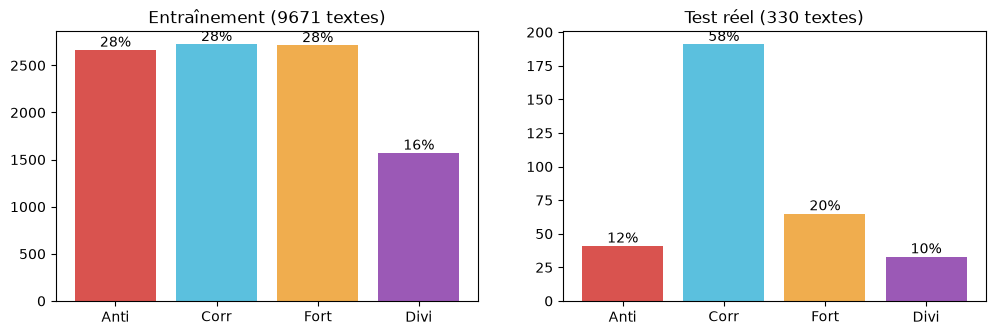

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, (nom, df) in zip(ax, [("Entraînement", train), ("Test réel", test)]):
    n = df["classe"].value_counts().reindex(CLASSES)
    a.bar(COURT, n, color=["#d9534f", "#5bc0de", "#f0ad4e", "#9b59b6"])
    for i, v in enumerate(n): a.text(i, v, f"{v / n.sum():.0%}", ha="center", va="bottom")
    a.set_title(f"{nom} ({len(df)} textes)")
plt.show()

Ce qu'on en retient : le train est équilibré, le test beaucoup moins. Il contient 58 % d'« Aura Correcte ». Un modèle qui répondrait toujours « Correcte » aurait donc déjà 58 % de bonnes réponses sans rien comprendre. C'est pour ça qu'on ne se fie pas à l'exactitude seule (partie 4).

In [4]:
print("Registres du TEST :")
print(test["type"].value_counts().head(8).to_string())
print("\nStyles de l'ENTRAÎNEMENT synthétique :")
print(charger(["data/train_synthetique.csv"])["style"].value_counts().head(8).to_string())

Registres du TEST :
type
discours        101
interjection     65
théâtre          35
poésie           22
question         20
réponse          18
roman            11
prose            10

Styles de l'ENTRAÎNEMENT synthétique :
style
politique           1795
poesie_classique    1400
argot internet            1381
moderne             1334
prose                470
quotidien            225
classique            212
juridique            137


In [5]:
def profil(df):
    t = df["texte"]
    return {"mots par texte": t.str.split().str.len().mean(),
            "% avec « ! »": t.str.contains("!").mean() * 100,
            "% avec emoji": t.str.contains(r"[\U0001F300-\U0001FAFF]").mean() * 100}
pd.DataFrame({"train synthétique": profil(charger(["data/train_synthetique.csv"])), "test réel": profil(test)}).round(1)

,train synthétique,test réel
mots par texte,26.4,11.4
% avec « ! »,4.9,31.5
% avec emoji,11.1,0.0


Ce qu'on en retient : nos premières données d'entraînement étaient générées (argot internet, SMS, bios), alors que le test contient de vrais textes (Assemblée nationale, théâtre, poésie, conférences de presse). Les deux n'ont pas le même style : peu d'emojis et plus de phrases courtes dans le test, par exemple.

C'est la principale difficulté du projet. Un modèle peut très bien marcher sur le style qu'il a vu et rater le reste. On a donc écrit des données supplémentaires dans le style du test (`train_registres`, `train_battle`, `train_joutes_reelles`), qu'on peut activer ou non dans les paramètres.

## 4. Comment on mesure les résultats

Nos classes ont un ordre : Anti < Correcte < Forte < Divine. Se tromper d'une case n'est pas aussi grave que de prendre un texte Anti pour du Divine.

On utilise donc le kappa quadratique. Il vaut 0 pour un modèle qui fait aussi bien que le hasard (ou qui répond toujours la même chose) et 1 pour un modèle parfait. Comme les écarts sont mis au carré, une grosse erreur coûte beaucoup plus qu'une petite.

On regarde aussi le F1-macro, qui donne le même poids à chaque classe (y compris la rare Divine), et la matrice de confusion.

In [6]:
RESULTATS = {}   # tableau de bord : chaque modèle y ajoute sa ligne

def evaluer(nom, y_vrai, y_pred, temps=None):
    RESULTATS[nom] = {"kappa": cohen_kappa_score(y_vrai, y_pred, weights="quadratic"),
                      "F1-macro": f1_score(y_vrai, y_pred, average="macro"),
                      "exactitude": accuracy_score(y_vrai, y_pred),
                      "temps (s)": temps}
    print(nom, {k: round(v, 3) for k, v in RESULTATS[nom].items() if v is not None})

evaluer("Toujours « Aura Correcte »", test["y"], np.ones(len(test), dtype=int))

Toujours « Aura Correcte » {'kappa': 0.0, 'F1-macro': 0.183, 'exactitude': 0.579}


## 5. Modèle 1 : TF-IDF et régression logistique

Le texte est transformé en vecteur de fréquences (TF-IDF), sur les mots mais aussi sur des morceaux de 2 à 5 lettres. Une régression logistique apprend ensuite à séparer les classes.

On commence par ce modèle parce qu'il est rapide, simple à expliquer, et que c'est la référence habituelle pour classer du texte. Les morceaux de lettres l'aident à reconnaître des mots mal écrits ou de l'argot.

In [7]:
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

if LANCER_BASELINE:
    baseline = make_pipeline(
        make_union(TfidfVectorizer(analyzer="word", ngram_range=BASE_NGRAM_MOTS, min_df=2, sublinear_tf=True),
                   TfidfVectorizer(analyzer="char_wb", ngram_range=BASE_NGRAM_CARACTERES, min_df=2, sublinear_tf=True)),
        LogisticRegression(C=BASE_C, class_weight="balanced", max_iter=3000))
    t0 = time.time(); baseline.fit(train["texte"], train["y"]); t = time.time() - t0
    print("validation :", round(cohen_kappa_score(val["y"], baseline.predict(val["texte"]), weights="quadratic"), 3))
    evaluer("1. Baseline TF-IDF", test["y"], baseline.predict(test["texte"]), t)

validation : 0.715
1. Baseline TF-IDF {'kappa': 0.166, 'F1-macro': 0.29, 'exactitude': 0.352, 'temps (s)': 8.733}


Ce qu'on en retient : `class_weight="balanced"` donne plus d'importance aux classes rares comme Divine. Entraînée uniquement sur les données synthétiques, cette baseline faisait 0,05 de kappa sur le test, presque le hasard. Avec les données ajoutées, elle s'améliore nettement.

## 6. Modèle 2 : un réseau de neurones codé à la main en NumPy

On n'utilise ici aucune librairie de deep learning. Le but est de montrer ce qui se passe vraiment pendant l'apprentissage.

Le réseau prend le TF-IDF en entrée (20 000 valeurs), passe par deux couches cachées de 256 puis 128 neurones avec ReLU, et sort 4 probabilités grâce au softmax.

À chaque pas d'apprentissage :
1. on calcule les probabilités (propagation avant) ;
2. on mesure l'erreur avec l'entropie croisée, qui est forte quand le modèle donne peu de chances à la bonne classe ;
3. on calcule le gradient de chaque poids avec la règle de la chaîne (rétropropagation) ;
4. on met les poids à jour avec Adam.

In [8]:
from scipy import sparse

class MLP:
    def __init__(self, n_entree, c1, c2, dropout, graine):
        self.rng = np.random.default_rng(graine); self.dropout = dropout
        tailles = [n_entree, c1, c2, 4]
        # Initialisation « He » : variance 2/n, adaptée à ReLU
        self.W = [self.rng.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(tailles[:-1], tailles[1:])]
        self.b = [np.zeros(b) for b in tailles[1:]]

    def avant(self, X, entrainement=False):
        self.cache, self.masques = [X], [None]; A = X
        for i in range(2):                                    # 2 couches cachées
            A = np.maximum(0, A @ self.W[i] + self.b[i])      # ReLU
            masque = np.ones_like(A)
            if entrainement:                                  # dropout inversé : on éteint des neurones et on compense l'échelle
                masque = (self.rng.random(A.shape) > self.dropout) / (1 - self.dropout); A = A * masque
            self.cache.append(A); self.masques.append(masque)
        Z = A @ self.W[2] + self.b[2]
        E = np.exp(Z - Z.max(1, keepdims=True))
        return E / E.sum(1, keepdims=True)                    # softmax

    def arriere(self, P, y, poids):
        w = poids[y]; dZ = P.copy(); dZ[np.arange(len(y)), y] -= 1; dZ *= (w / w.sum())[:, None]   # dérivée softmax + entropie croisée
        grads = []
        for i in (2, 1, 0):
            A = self.cache[i]
            grads.append((np.asarray(A.T @ dZ), dZ.sum(0)))
            if i > 0: dZ = (dZ @ self.W[i].T) * self.masques[i] * (self.cache[i] > 0)   # règle de la chaîne : dropout puis ReLU
        return grads[::-1]

def perte(P, y, poids):
    return float(np.sum(poids[y] * -np.log(P[np.arange(len(y)), y] + 1e-12)) / poids[y].sum())

In [9]:
class Adam:   # optimiseur Adam écrit à la main : moyenne des gradients (m) et de leurs carrés (v), avec correction de biais
    def __init__(self, params, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t = lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]
    def pas(self, params, grads):
        self.t += 1
        for p, g, m, v in zip(params, grads, self.m, self.v):
            m[:] = self.b1 * m + (1 - self.b1) * g;  v[:] = self.b2 * v + (1 - self.b2) * g ** 2
            p -= self.lr * (m / (1 - self.b1 ** self.t)) / (np.sqrt(v / (1 - self.b2 ** self.t)) + self.eps)

Avant d'entraîner, on vérifie que notre rétropropagation est juste. On prend un poids, on calcule son gradient « à la main », puis on l'estime numériquement en bougeant légèrement le poids : (perte(w+ε) − perte(w−ε)) / 2ε. Si les deux valeurs sont presque identiques, le calcul est bon.

In [10]:
if LANCER_MLP:
    tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=MLP_NB_FEATURES)
    X_tr = sparse.csr_matrix(tfidf.fit_transform(train["texte"]), dtype=np.float64)   # ajusté sur le train SEULEMENT
    X_va, X_te = tfidf.transform(val["texte"]), tfidf.transform(test["texte"])
    y_tr = train["y"].values
    poids = len(y_tr) / (4 * np.bincount(y_tr, minlength=4))     # poids des classes (Divine compte plus)

    # gradient check sur 8 textes, sur un poids de la dernière couche
    net = MLP(X_tr.shape[1], 16, 8, 0.0, GRAINE)
    Xp, yp = X_tr[:8], y_tr[:8]
    g = net.arriere(net.avant(Xp), yp, poids)[2][0][3, 1]
    eps = 1e-5; net.W[2][3, 1] += eps; p1 = perte(net.avant(Xp), yp, poids)
    net.W[2][3, 1] -= 2 * eps; p2 = perte(net.avant(Xp), yp, poids); net.W[2][3, 1] += eps
    print(f"gradient analytique {g:.8f} | numérique {(p1 - p2) / (2 * eps):.8f}")

gradient analytique 0.00021539 | numérique 0.00021539


2. MLP NumPy (de zéro) {'kappa': 0.237, 'F1-macro': 0.307, 'exactitude': 0.345, 'temps (s)': 186.692}


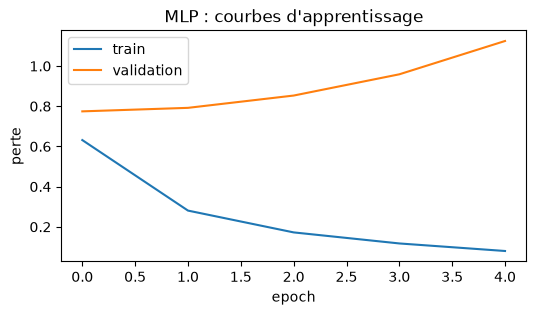

In [11]:
if LANCER_MLP:
    net = MLP(X_tr.shape[1], MLP_COUCHE_1, MLP_COUCHE_2, MLP_DROPOUT, GRAINE)
    params = net.W + net.b; opt = Adam(params, MLP_LR)
    historique, meilleur, attente, t0 = {"train": [], "val": []}, (np.inf, None), 0, time.time()
    for epoch in range(MLP_EPOCHS_MAX):
        ordre = np.random.permutation(len(y_tr)); total = 0
        for i in range(0, len(ordre), MLP_BATCH):                     # mini-batches
            lot = ordre[i:i + MLP_BATCH]
            P = net.avant(X_tr[lot], entrainement=True)
            total += perte(P, y_tr[lot], poids) * len(lot)
            (gW0, gb0), (gW1, gb1), (gW2, gb2) = net.arriere(P, y_tr[lot], poids)
            opt.pas(params, [gW0, gW1, gW2, gb0, gb1, gb2])
        pv = perte(net.avant(X_va), val["y"].values, poids)
        historique["train"].append(total / len(y_tr)); historique["val"].append(pv)
        if pv < meilleur[0]: meilleur, attente = (pv, [p.copy() for p in params]), 0
        else:
            attente += 1
            if attente >= MLP_PATIENCE: break                         # early stopping
    for p, best in zip(params, meilleur[1]): p[:] = best               # on garde la meilleure epoch
    evaluer("2. MLP NumPy (de zéro)", test["y"], net.avant(X_te).argmax(1), time.time() - t0)
    plt.figure(figsize=(6, 3)); plt.plot(historique["train"], label="train"); plt.plot(historique["val"], label="validation")
    plt.xlabel("epoch"); plt.ylabel("perte"); plt.legend(); plt.title("MLP : courbes d'apprentissage"); plt.show()

Ce qu'on en retient : quand la perte de validation remonte alors que celle du train continue de baisser, le modèle commence à apprendre par cœur, c'est le surapprentissage. L'early stopping arrête l'entraînement à ce moment-là et garde la meilleure epoch. Le dropout aide aussi à limiter le problème.

## 7. Modèle 3 : un BiLSTM entraîné de zéro

Le TF-IDF ne tient pas compte de l'ordre des mots. Le LSTM, lui, lit le texte mot après mot et garde une mémoire de ce qu'il a lu. Le « Bi » signifie qu'il le lit dans les deux sens, ce qui permet de bien prendre en compte la fin de la phrase, souvent là où se trouve la chute.

Le fonctionnement : on découpe le texte en mots, on donne un numéro à chaque mot du train, chaque numéro devient un vecteur appris (l'embedding), le BiLSTM lit la séquence, puis on résume la phrase (maximum et moyenne) avant de classer. Rien n'est pré-entraîné.

In [12]:
import torch.nn as nn

def tokeniser(t):   # minuscules ; « l'aura » -> « l' » + « aura » ; garde ponctuation et emojis
    return re.findall(r"[^\W_]+['’](?=[^\W_])|[^\W_]+|[^\w\s]", t.lower())

class BiLSTM(nn.Module):
    def __init__(self, n_mots):
        super().__init__()
        self.emb = nn.Embedding(n_mots, LSTM_EMBEDDING, padding_idx=0)
        self.lstm = nn.LSTM(LSTM_EMBEDDING, LSTM_CACHE, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(LSTM_DROPOUT)
        self.sortie = nn.Sequential(nn.Linear(4 * LSTM_CACHE, LSTM_CACHE), nn.ReLU(), nn.Dropout(LSTM_DROPOUT), nn.Linear(LSTM_CACHE, 4))
    def forward(self, x):
        masque = (x != 0).unsqueeze(-1).float()
        h, _ = self.lstm(self.drop(self.emb(x)))
        h_max = h.masked_fill(masque == 0, -1e9).max(1).values          # le mot « le plus fort »
        h_moy = (h * masque).sum(1) / masque.sum(1).clamp(min=1)       # le ton général
        return self.sortie(torch.cat([h_max, h_moy], -1))

print(tokeniser("Wesh, t'es où ?? 😭 L'aura +1000 !"))

['wesh', ',', "t'", 'es', 'où', '?', '?', '😭', "l'", 'aura', '+', '1000', '!']


In [13]:
if LANCER_BILSTM:
    compte = collections.Counter(m for t in train["texte"] for m in tokeniser(t))
    vocab = {m: i + 2 for i, m in enumerate(m for m, c in compte.items() if c >= 2)}   # 0 = remplissage, 1 = mot inconnu
    def encoder(textes):
        ids = [[vocab.get(m, 1) for m in tokeniser(t)][:LSTM_LONGUEUR_MAX] or [1] for t in textes]
        X = torch.zeros(len(ids), max(map(len, ids)), dtype=torch.long)
        for i, s in enumerate(ids): X[i, :len(s)] = torch.tensor(s)
        return X
    Xtr, Xva, Xte = encoder(train["texte"]), encoder(val["texte"]), encoder(test["texte"])
    ytr, yva = torch.tensor(train["y"].values), torch.tensor(val["y"].values)
    poids_t = torch.tensor(len(ytr) / (4 * np.bincount(train["y"].values, minlength=4)), dtype=torch.float, device=DEVICE)
    print(f"vocabulaire : {len(vocab)} mots (vus au moins 2 fois dans le train)")

    modele = BiLSTM(len(vocab) + 2).to(DEVICE)
    opt = torch.optim.Adam(modele.parameters(), lr=LSTM_LR)
    critere = nn.CrossEntropyLoss(weight=poids_t)
    meilleur, attente, t0 = (np.inf, None), 0, time.time()
    for epoch in range(LSTM_EPOCHS_MAX):
        modele.train()
        for i in torch.randperm(len(ytr)).split(LSTM_BATCH):
            opt.zero_grad(); l = critere(modele(Xtr[i].to(DEVICE)), ytr[i].to(DEVICE)); l.backward()
            nn.utils.clip_grad_norm_(modele.parameters(), 1.0)          # gradient clipping : évite les explosions
            opt.step()
        modele.eval()
        with torch.no_grad(): pv = critere(modele(Xva.to(DEVICE)), yva.to(DEVICE)).item()
        print(f"epoch {epoch + 1} : perte validation {pv:.3f}")
        if pv < meilleur[0]: meilleur, attente = (pv, {k: v.clone() for k, v in modele.state_dict().items()}), 0
        else:
            attente += 1
            if attente >= LSTM_PATIENCE: break
    modele.load_state_dict(meilleur[1]); modele.eval()
    with torch.no_grad(): pred = torch.cat([modele(Xte[i:i + 256].to(DEVICE)).argmax(1).cpu() for i in range(0, len(Xte), 256)])
    evaluer("3. BiLSTM (de zéro)", test["y"], pred.numpy(), time.time() - t0)

vocabulaire : 4261 mots (vus au moins 2 fois dans le train)


epoch 1 : perte validation 0.968


epoch 2 : perte validation 0.844


epoch 3 : perte validation 0.785


epoch 4 : perte validation 0.813


epoch 5 : perte validation 0.923


epoch 6 : perte validation 1.103
3. BiLSTM (de zéro) {'kappa': 0.135, 'F1-macro': 0.28, 'exactitude': 0.333, 'temps (s)': 7.041}


Ce qu'on en retient : le BiLSTM ne connaît que les mots vus au moins deux fois dans nos quelques milliers de textes. Tous les autres deviennent « inconnu ». Il ne comprend donc pas vraiment le français, et c'est la limite d'un modèle entraîné de zéro.

## 8. Modèle 4 : CamemBERT, un modèle pré-entraîné

CamemBERT est un Transformer qui a déjà été entraîné sur 138 Go de textes en français. Il connaît la langue, y compris l'ironie et les tournures littéraires. Nous, on se contente de l'ajuster sur nos données (fine-tuning).

On peut l'utiliser de deux façons (paramètre `CAMEMBERT_MODE`) :
- en classification, il choisit directement une des 4 classes ;
- en régression, il prédit le score de −100 à +100, puis on applique les seuils. Cette méthode respecte l'ordre des classes et marche mieux chez nous.

L'entraînement prend environ 8 minutes sur GPU. Si `ENTRAINER_CAMEMBERT = False`, on recharge les prédictions qu'on avait déjà calculées.

In [14]:
def score_vers_classe(s):   # seuils officiels
    return 0 if s <= -10.5 else 1 if s <= 24.5 else 2 if s <= 74.5 else 3

if ENTRAINER_CAMEMBERT:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
    reg = CAMEMBERT_MODE == "regression"
    tok = AutoTokenizer.from_pretrained(CAMEMBERT_MODELE)
    cm = AutoModelForSequenceClassification.from_pretrained(CAMEMBERT_MODELE, num_labels=1 if reg else 4)
    tr_cm = train.dropna(subset=["score"]) if reg else train
    class Jeu(torch.utils.data.Dataset):
        def __init__(self, df): self.enc = tok(list(df["texte"]), truncation=True, max_length=CAMEMBERT_LONGUEUR_MAX); self.y = list(df["score"] / 100 if reg else df["y"])
        def __len__(self): return len(self.y)
        def __getitem__(self, i): return {**{k: v[i] for k, v in self.enc.items()}, "labels": self.y[i]}
    args = TrainingArguments("models/notebook_camembert", num_train_epochs=CAMEMBERT_EPOCHS, learning_rate=CAMEMBERT_LR,
                             per_device_train_batch_size=CAMEMBERT_BATCH, warmup_steps=0.1, weight_decay=0.01,
                             fp16=DEVICE == "cuda", save_strategy="no", report_to="none", seed=GRAINE)
    t0 = time.time()
    trainer = Trainer(model=cm, args=args, train_dataset=Jeu(tr_cm), data_collator=DataCollatorWithPadding(tok))
    trainer.train()
    sortie = trainer.predict(Jeu(test.assign(score=test["score"].fillna(0)))).predictions
    pred = [score_vers_classe(s * 100) for s in sortie.reshape(-1)] if reg else sortie.argmax(1)
    evaluer(f"4. CamemBERT {CAMEMBERT_MODE} (entraîné ici)", test["y"], pred, time.time() - t0)
else:
    p1 = pd.read_csv("results/predictions_camembert_regression.csv", encoding="utf-8-sig")
    evaluer("4a. CamemBERT régression (phase 1 : données synthétiques)", test["y"], p1["prediction"].map(CLASSES.index), 354)
    p2 = pd.read_csv("results/predictions_phase2.csv", encoding="utf-8-sig")
    evaluer("4b. ⭐ CamemBERT phase 2 (modèle retenu)", test["y"], p2["prediction"].map(CLASSES.index), 30 * 60 + 3 * 8 * 60)

4a. CamemBERT régression (phase 1 : données synthétiques) {'kappa': 0.323, 'F1-macro': 0.343, 'exactitude': 0.479, 'temps (s)': 354}
4b. ⭐ CamemBERT phase 2 (modèle retenu) {'kappa': 0.389, 'F1-macro': 0.455, 'exactitude': 0.594, 'temps (s)': 3240}


### Le modèle qu'on a retenu

Pour arriver au modèle final, on a fait plusieurs choses :

1. On a ajouté au train des textes écrits dans le style du test : registres de l'Assemblée et du théâtre, battle rap, vraies répliques du domaine public.
2. Pour choisir entre les modèles, on a utilisé une validation dans ce même style (`val_domaine.csv`, 240 textes), plutôt qu'une validation synthétique beaucoup trop facile.
3. On a entraîné plusieurs CamemBERT : un camembert-large en régression (trois fois plus gros), et trois CamemBERT en classification avec des graines différentes, où les erreurs sur la classe Divine comptent trois fois plus parce qu'elle est rare.
4. On fait la moyenne de leurs scores (60 % pour le large, 40 % pour les trois autres), puis on applique des seuils ajustés (−12 / 36 / 69).

Les poids et les seuils ont été choisis uniquement sur la validation, avant de regarder le test. Le code complet est dans `scripts/train_camembert_v2.py` et `scripts/phase2_final.py`.

## 9. Comparaison de tous les modèles

Tous les modèles sont évalués sur le même test de 330 vrais textes.

,kappa,F1-macro,exactitude,temps (s)
Toujours « Aura Correcte »,0.000,0.18,58%,
3. BiLSTM (de zéro),0.135,0.28,33%,7
1. Baseline TF-IDF,0.166,0.29,35%,9
2. MLP NumPy (de zéro),0.237,0.31,35%,187
4a. CamemBERT régression (phase 1 : données synthétiques),0.323,0.34,48%,354
4b. ⭐ CamemBERT phase 2 (modèle retenu),0.389,0.45,59%,3240


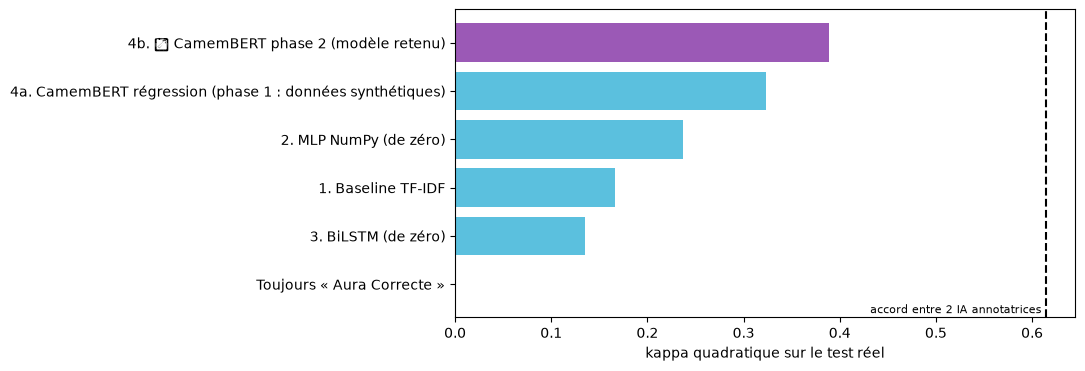

In [15]:
tableau = pd.DataFrame(RESULTATS).T.sort_values("kappa")
display(tableau.style.format({"kappa": "{:.3f}", "F1-macro": "{:.2f}", "exactitude": "{:.0%}", "temps (s)": lambda v: "" if pd.isna(v) else f"{v:.0f}"}))
plt.figure(figsize=(8, 0.5 * len(tableau) + 1))
plt.barh(tableau.index, tableau["kappa"], color=["#9b59b6" if "⭐" in n else "#5bc0de" for n in tableau.index])
plt.axvline(0.614, ls="--", c="k"); plt.text(0.61, -0.6, "accord entre 2 IA annotatrices", ha="right", fontsize=8)
plt.xlabel("kappa quadratique sur le test réel"); plt.show()

Attention, les chiffres du MLP et du BiLSTM obtenus ici ne sont pas exactement ceux de `RESULTATS.md`. Ils dépendent des paramètres de la partie 1. Par défaut, on les entraîne sur toutes les données et on arrête l'entraînement grâce à `val_domaine`. Le MLP y gagne (environ 0,24 au lieu de 0,18). Le BiLSTM, lui, s'arrête trop tôt et perd des points : c'est un bon exemple pour montrer que le choix de la validation influence beaucoup le résultat. Les deux restent nettement derrière CamemBERT.

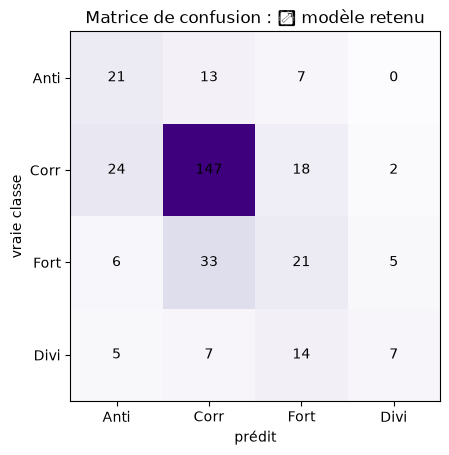

In [16]:
# matrice de confusion du modèle retenu (celui servi par la WebApp)
pred_best = pd.read_csv("results/predictions_phase2.csv", encoding="utf-8-sig")["prediction"].map(CLASSES.index)
meilleur_nom = "⭐ modèle retenu"
m = confusion_matrix(test["y"], pred_best, labels=range(4))
plt.imshow(m, cmap="Purples"); plt.xticks(range(4), COURT); plt.yticks(range(4), COURT)
for i in range(4):
    for j in range(4): plt.text(j, i, m[i, j], ha="center", va="center")
plt.xlabel("prédit"); plt.ylabel("vraie classe"); plt.title(f"Matrice de confusion : {meilleur_nom}"); plt.show()

Ce qu'on en retient :
- La diagonale correspond aux bonnes réponses. La plupart des erreurs tombent juste à côté : le modèle se trompe rarement de plus d'une classe.
- Divine reste la classe la plus difficile. Ce sont souvent des citations célèbres, et leur aura vient aussi de leur réputation, que le modèle ne connaît pas.
- La grosse différence entre CamemBERT et nos réseaux faits de zéro vient du pré-entraînement : CamemBERT comprend le français, eux non.
- Il y a une limite : deux IA qui annotent le même test ne sont d'accord qu'à 0,61. Un modèle peut difficilement faire mieux que ceux qui l'ont annoté.

## 10. Démo

On teste le modèle retenu, le même que celui utilisé par la WebApp. Pour essayer d'autres phrases, il suffit de modifier `PHRASES_DEMO` dans les paramètres.

In [17]:
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
from transformers import AutoTokenizer, AutoModelForSequenceClassification
choix = json.load(open("results/p2_choix.json", encoding="utf-8"))
retenu = choix["candidats"][choix["meilleur"]]
CENTRES = np.array([-55, 7, 50, 87])   # score « moyen » de chaque classe, pour convertir des probabilités en score

def score(dossier, textes):
    tok = AutoTokenizer.from_pretrained(dossier); m = AutoModelForSequenceClassification.from_pretrained(dossier).to(DEVICE).eval()
    with torch.no_grad(): o = m(**tok(textes, padding=True, truncation=True, return_tensors="pt").to(DEVICE)).logits.cpu()
    return o.reshape(-1).numpy() * 100 if o.shape[1] == 1 else o.softmax(1).numpy() @ CENTRES

s = sum(w * score(f"models/{nom}/final", PHRASES_DEMO) for nom, w in retenu["composants"].items())
classes_pred = np.digitize(s, retenu["seuils"])
pd.DataFrame({"phrase": PHRASES_DEMO, "score": s.round(0), "classe prédite": [CLASSES[k] for k in classes_pred]})

,phrase,score,classe prédite
0,Je me suis chié dessus,-42.0,Anti-Aura
1,"La bière c'est comme ma femme, brune et amer",-44.0,Anti-Aura
2,fort en chocolat,-22.0,Anti-Aura
3,"dab dab, six-seven",-43.0,Anti-Aura
4,un accident de train a eu lieu en espagne ce s...,-4.0,Aura Correcte
5,"En imposer pour ne pas avoir à imposer, voilà ...",68.0,Forte Aura
6,"Loin des yeux, loin du cœur",-6.0,Aura Correcte


## 11. Conclusion

| Modèle | Kappa sur le test |
|---|---|
| Toujours « Correcte » | 0,00 |
| TF-IDF, données synthétiques seules | 0,05 |
| Réseaux faits de zéro (MLP, BiLSTM), données synthétiques | environ 0,18 à 0,22 |
| CamemBERT, données synthétiques | 0,32 |
| CamemBERT, données dans le style du test et ensemble (modèle retenu) | 0,39 |

Ce qu'on retient du projet :

1. Les données ont compté plus que le choix du modèle. Notre plus gros progrès vient des textes qui ressemblent au vrai usage.
2. Le pré-entraînement fait une vraie différence : CamemBERT dépasse largement les modèles entraînés de zéro.
3. Notre test a été annoté par une seule IA, et deux IA ne tombent d'accord qu'à 0,61. Pour aller plus loin, il faudrait faire annoter les textes par des humains.

Toutes les expériences en détail (recherche d'hyperparamètres, variantes de CamemBERT, analyse des erreurs) sont dans `RESULTATS.md`.